In [121]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(context='notebook', style='darkgrid', font='sans-serif')

In [122]:
train_df = pd.read_csv('../files/cars_train.csv')
test_df = pd.read_csv('../files/cars_test.csv')

In [123]:
print(f"Train Data size -> {train_df.shape}")
print(f"Test Data size -> {test_df.shape}")

Train Data size -> (1500, 14)
Test Data size -> (500, 14)


In [124]:
train_df.head()

,car_id,brand,model_year,mileage_km,engine_size_l,horsepower,fuel_type,transmission,body_type,condition,owners_count,accidents_reported,fuel_consumption_l,price_usd
0,CAR_00001,Hyundai,2016,214700,1.5,102,Petrol,Automatic,Sedan,Very Good,1,1,5.9,4100
1,CAR_00002,Audi,2015,195600,2.5,192,Petrol,Automatic,Sedan,Good,1,0,7.4,19300
2,CAR_00003,Honda,2023,44800,1.6,126,Petrol,Automatic,Crossover,Very Good,2,1,4.8,15600
3,CAR_00004,Toyota,2015,203400,1.6,116,Petrol,Manual,Sedan,Good,1,0,4.5,4900
4,CAR_00005,Chevrolet,2016,150400,1.4,94,Petrol,Manual,SUV,Very Good,2,1,4.5,2700


In [125]:
train_df.tail()

,car_id,brand,model_year,mileage_km,engine_size_l,horsepower,fuel_type,transmission,body_type,condition,owners_count,accidents_reported,fuel_consumption_l,price_usd
1495,CAR_01496,Toyota,2015,215600,1.5,103,Petrol,Automatic,SUV,Very Good,1,0,4.7,5200
1496,CAR_01497,Toyota,2023,62400,1.5,103,Petrol,Manual,Hatchback,Good,1,2,5.2,9200
1497,CAR_01498,Kia,2023,74900,1.2,88,Petrol,Manual,SUV,Good,1,0,4.5,6900
1498,CAR_01499,Hyundai,2014,189200,1.6,125,Petrol,Automatic,Sedan,Good,1,0,5.7,4600
1499,CAR_01500,BMW,2021,61500,4.0,317,Petrol,Manual,Sedan,Good,2,0,11.6,45000


In [126]:
print(f"Train Data Types -> \n{train_df.dtypes}")

Train Data Types -> 
car_id                    str
brand                     str
model_year              int64
mileage_km              int64
engine_size_l         float64
horsepower              int64
fuel_type                 str
transmission              str
body_type                 str
condition                 str
owners_count            int64
accidents_reported      int64
fuel_consumption_l    float64
price_usd               int64
dtype: object


In [127]:
print(train_df.info())

<class 'pandas.DataFrame'>
RangeIndex: 1500 entries, 0 to 1499
Data columns (total 14 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   car_id              1500 non-null   str    
 1   brand               1500 non-null   str    
 2   model_year          1500 non-null   int64  
 3   mileage_km          1500 non-null   int64  
 4   engine_size_l       1500 non-null   float64
 5   horsepower          1500 non-null   int64  
 6   fuel_type           1500 non-null   str    
 7   transmission        1500 non-null   str    
 8   body_type           1500 non-null   str    
 9   condition           1500 non-null   str    
 10  owners_count        1500 non-null   int64  
 11  accidents_reported  1500 non-null   int64  
 12  fuel_consumption_l  1500 non-null   float64
 13  price_usd           1500 non-null   int64  
dtypes: float64(2), int64(6), str(6)
memory usage: 164.2 KB
None


In [128]:
print(f"Nulls count -> {train_df.isnull().sum().sum()}")

Nulls count -> 0


In [129]:
print(train_df.describe())

        model_year     mileage_km  engine_size_l   horsepower  owners_count  \
count  1500.000000    1500.000000    1500.000000  1500.000000   1500.000000   
mean   2018.333333  131080.666667       1.860000   136.231333      1.859333   
std       3.972330   72314.901850       0.648084    57.919216      0.903377   
min    2010.000000   10200.000000       1.200000    75.000000      1.000000   
25%    2015.000000   74825.000000       1.500000   100.000000      1.000000   
50%    2019.000000  120200.000000       1.600000   113.000000      2.000000   
75%    2022.000000  176825.000000       2.000000   150.000000      2.000000   
max    2025.000000  423600.000000       4.400000   369.000000      4.000000   

       accidents_reported  fuel_consumption_l      price_usd  
count         1500.000000         1500.000000    1500.000000  
mean             0.267333            5.660667   12837.133333  
std              0.544117            2.096036   13666.263777  
min              0.000000           

In [130]:
Q1, Q3 = train_df['price_usd'].quantile([0.25, 0.75])
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = train_df[(train_df['price_usd'] < lower_bound) | (train_df['price_usd'] > upper_bound)]

print(f"Lower bound -> {lower_bound}")
print(f"Upper bound -> {upper_bound}")
print(f"IQR -> {IQR}")
print(f"Outliers count -> {len(outliers)}")

# price usd ni describe bilan korganimizda umumiy manoda outlier yoq desak boladi chunki hammasi mantiqli

Lower bound -> -8600.0
Upper bound -> 27400.0
IQR -> 9000.0
Outliers count -> 184


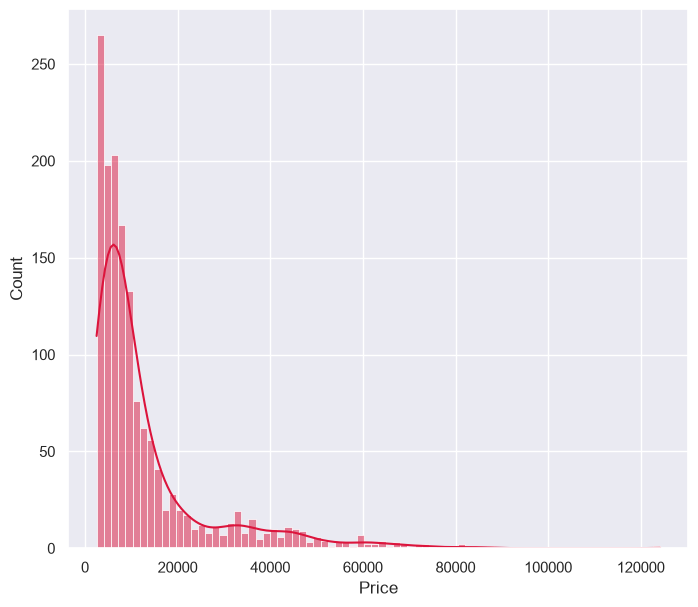

In [131]:
plt.figure(figsize=(8, 7))
sns.histplot(data=train_df, x='price_usd', kde=True, color="crimson" )
plt.xlabel('Price')
plt.show()

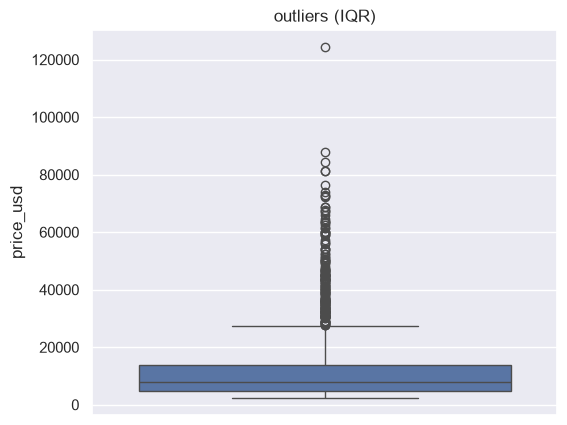

In [132]:
plt.figure(figsize=(6, 5))
sns.boxplot(data=train_df, y='price_usd')
plt.title('outliers (IQR)')
plt.show()
# outlierlar asosan upper bounddan teppadaligini korishimiz mumkin chunki qimmat mashinalar kop

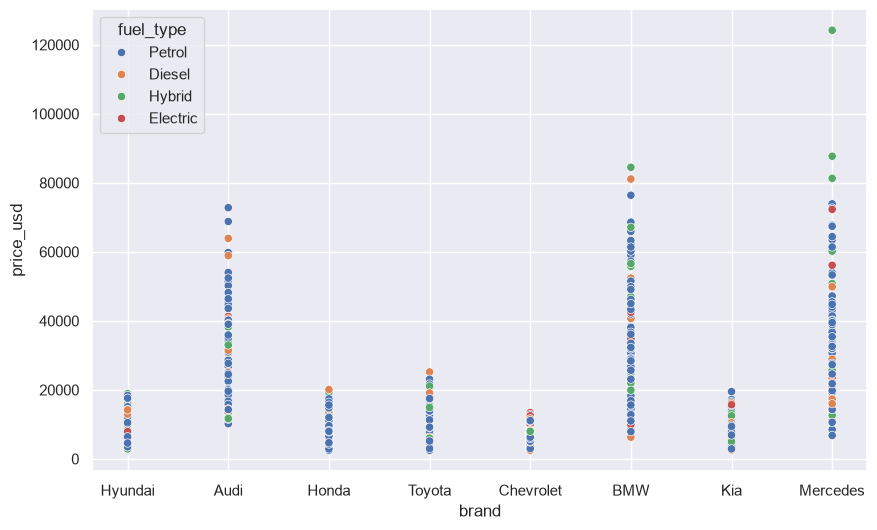

In [133]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=train_df, x='brand', y='price_usd', hue='fuel_type')
plt.show()

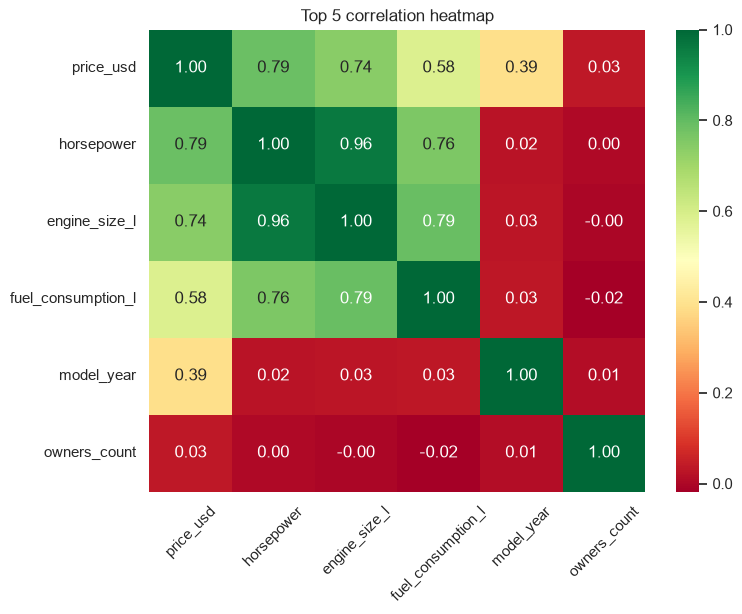

In [134]:
nums = train_df.select_dtypes(include=['number'])

top_corr = nums.corr()['price_usd'].sort_values(ascending=False).head(6).index

plt.figure(figsize=(8, 6))
sns.heatmap(nums[top_corr].corr(), cmap='RdYlGn', annot=True, fmt='.2f')
plt.title("Top 5 correlation heatmap")
plt.xticks(rotation=45)
plt.show()

In [135]:
target_col = 'price_usd'

X_train = train_df.drop(columns=[target_col])
X_test = test_df.drop(columns=[target_col])

y_train = train_df[target_col]
y_test = test_df[target_col]

print(f"X Train shape -> {X_train.shape}")
print(f"X Test shape -> {X_test.shape}")
print(f"Y Train shape -> {y_train.shape}")
print(f"Y Test shape -> {y_test.shape}")

X Train shape -> (1500, 13)
X Test shape -> (500, 13)
Y Train shape -> (1500,)
Y Test shape -> (500,)


In [136]:
drop_cols = ['car_id']

X_train = X_train.drop(columns=drop_cols)
X_test = X_test.drop(columns=drop_cols)

print(f"X Train shape after dropping -> {X_train.shape}")
print(f"X Test shape after dropping -> {X_test.shape}")

X Train shape after dropping -> (1500, 12)
X Test shape after dropping -> (500, 12)


In [137]:
print(f"mavjud ustunlar -> {X_train.columns}")

mavjud ustunlar -> Index(['brand', 'model_year', 'mileage_km', 'engine_size_l', 'horsepower',
       'fuel_type', 'transmission', 'body_type', 'condition', 'owners_count',
       'accidents_reported', 'fuel_consumption_l'],
      dtype='str')


In [138]:
X_train.info()

<class 'pandas.DataFrame'>
RangeIndex: 1500 entries, 0 to 1499
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   brand               1500 non-null   str    
 1   model_year          1500 non-null   int64  
 2   mileage_km          1500 non-null   int64  
 3   engine_size_l       1500 non-null   float64
 4   horsepower          1500 non-null   int64  
 5   fuel_type           1500 non-null   str    
 6   transmission        1500 non-null   str    
 7   body_type           1500 non-null   str    
 8   condition           1500 non-null   str    
 9   owners_count        1500 non-null   int64  
 10  accidents_reported  1500 non-null   int64  
 11  fuel_consumption_l  1500 non-null   float64
dtypes: float64(2), int64(5), str(5)
memory usage: 140.8 KB


In [139]:
X_train.head()

,brand,model_year,mileage_km,engine_size_l,horsepower,fuel_type,transmission,body_type,condition,owners_count,accidents_reported,fuel_consumption_l
0,Hyundai,2016,214700,1.5,102,Petrol,Automatic,Sedan,Very Good,1,1,5.9
1,Audi,2015,195600,2.5,192,Petrol,Automatic,Sedan,Good,1,0,7.4
2,Honda,2023,44800,1.6,126,Petrol,Automatic,Crossover,Very Good,2,1,4.8
3,Toyota,2015,203400,1.6,116,Petrol,Manual,Sedan,Good,1,0,4.5
4,Chevrolet,2016,150400,1.4,94,Petrol,Manual,SUV,Very Good,2,1,4.5


In [140]:
from datetime import date
def feature_engineering(df):
	df = df.copy()

	current_year = date.today().year
	df['model_age'] = current_year - df['model_year']

	df['power_density'] = df['horsepower'] / df['engine_size_l']
	df['per_year_mileage_km'] = df['mileage_km'] / df['model_age']
	df['per_horsepower_fuel_consumption'] = df['fuel_consumption_l'] / df['horsepower']

	return df

X_train = feature_engineering(X_train)
X_test = feature_engineering(X_test)

print(f"X Train shape after feature engineering -> {X_train.shape}")
print(f"X Test shape after feature engineering -> {X_test.shape}")

X Train shape after feature engineering -> (1500, 16)
X Test shape after feature engineering -> (500, 16)


In [141]:
X_train['condition'].value_counts()

condition
Good         597
Very Good    494
Excellent    236
Fair         173
Name: count, dtype: int64

In [142]:
from sklearn.preprocessing import OneHotEncoder

label_encoder = {
	"Good" : 1,
	"Very Good": 2, 
	"Excellent": 3,
	"Fair": 4
}

X_train['condition'] = X_train['condition'].map(label_encoder)
X_test['condition'] = X_test['condition'].map(label_encoder)

ohe_cols = ['brand', 'fuel_type', 'transmission', 'body_type']
ohe = OneHotEncoder(handle_unknown='ignore', sparse_output=False)

train_encoded = ohe.fit_transform(X_train[ohe_cols])
test_encoded = ohe.transform(X_test[ohe_cols])

ohe_feature_name = ohe.get_feature_names_out(ohe_cols)

df_train_encoded = pd.DataFrame(train_encoded, columns=ohe_feature_name, index=X_train.index)
df_test_encoded = pd.DataFrame(test_encoded, columns=ohe_feature_name, index=X_test.index)

X_train = pd.concat([X_train.drop(columns=ohe_cols), df_train_encoded], axis=1)
X_test = pd.concat([X_test.drop(columns=ohe_cols), df_test_encoded], axis=1)

print(f"X Train shape after encoding -> {X_train.shape}")
print(f"X Test shape after encoding -> {X_test.shape}")

X Train shape after encoding -> (1500, 30)
X Test shape after encoding -> (500, 30)


In [148]:
X_train.describe()

,model_year,mileage_km,engine_size_l,horsepower,condition,owners_count,accidents_reported,fuel_consumption_l,model_age,power_density,...,fuel_type_Diesel,fuel_type_Electric,fuel_type_Hybrid,fuel_type_Petrol,transmission_Automatic,transmission_Manual,body_type_Crossover,body_type_Hatchback,body_type_SUV,body_type_Sedan
count,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000,...,1500.000000,1500.00000,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000
mean,2018.333333,131080.666667,1.860000,136.231333,1.990000,1.859333,0.267333,5.660667,7.666667,72.152984,...,0.140000,0.03800,0.141333,0.680667,0.714667,0.285333,0.086667,0.140667,0.318000,0.454667
std,3.972330,72314.901850,0.648084,57.919216,1.008586,0.903377,0.544117,2.096036,3.972330,8.491932,...,0.347103,0.19126,0.348481,0.466374,0.451724,0.451724,0.281440,0.347793,0.465855,0.498107
min,2010.000000,10200.000000,1.200000,75.000000,1.000000,1.000000,0.000000,0.000000,1.000000,50.625000,...,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,2015.000000,74825.000000,1.500000,100.000000,1.000000,1.000000,0.000000,4.500000,4.000000,66.250000,...,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,2019.000000,120200.000000,1.600000,113.000000,2.000000,2.000000,0.000000,5.200000,7.000000,70.833333,...,0.000000,0.00000,0.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,2022.000000,176825.000000,2.000000,150.000000,3.000000,2.000000,0.000000,6.300000,11.000000,77.525000,...,0.000000,0.00000,0.000000,1.000000,1.000000,1.000000,0.000000,0.000000,1.000000,1.000000
max,2025.000000,423600.000000,4.400000,369.000000,4.000000,4.000000,2.000000,13.600000,16.000000,103.500000,...,1.000000,1.00000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [149]:
X_train.columns

Index(['model_year', 'mileage_km', 'engine_size_l', 'horsepower', 'condition',
       'owners_count', 'accidents_reported', 'fuel_consumption_l', 'model_age',
       'power_density', 'per_year_mileage_km',
       'per_horsepower_fuel_consumption', 'brand_Audi', 'brand_BMW',
       'brand_Chevrolet', 'brand_Honda', 'brand_Hyundai', 'brand_Kia',
       'brand_Mercedes', 'brand_Toyota', 'fuel_type_Diesel',
       'fuel_type_Electric', 'fuel_type_Hybrid', 'fuel_type_Petrol',
       'transmission_Automatic', 'transmission_Manual', 'body_type_Crossover',
       'body_type_Hatchback', 'body_type_SUV', 'body_type_Sedan'],
      dtype='str')

In [150]:
from sklearn.preprocessing import StandardScaler

scaler_cols = [
	  "model_year",
    "mileage_km",
    "engine_size_l",
    "horsepower",
    "fuel_consumption_l",
    "model_age",
    "power_density",
    "per_year_mileage_km",
    "per_horsepower_fuel_consumption",
]

sc = StandardScaler()

X_train[scaler_cols] = sc.fit_transform(X_train[scaler_cols])
X_test[scaler_cols] = sc.transform(X_test[scaler_cols])


print("Scaling successfully completed!")
print(X_train[scaler_cols].mean().round(2))

Scaling successfully completed!
model_year                         0.0
mileage_km                         0.0
engine_size_l                     -0.0
horsepower                        -0.0
fuel_consumption_l                -0.0
model_age                         -0.0
power_density                      0.0
per_year_mileage_km                0.0
per_horsepower_fuel_consumption   -0.0
dtype: float64


In [152]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.dummy import DummyRegressor

baseline = DummyRegressor(strategy='mean')
baseline.fit(X_train, y_train)

baseline_prediction = baseline.predict(X_test)

mae = mean_absolute_error(y_test, baseline_prediction)
mse = mean_squared_error(y_test, baseline_prediction)
r2 = r2_score(y_test, baseline_prediction)

print("BASELINE RESULT")
print(f"MAE -> {mae:.4f}")
print(f"MSE -> {mse:.4f}")
print(f"R^2 -> {r2:.4f}")

BASELINE RESULT
MAE -> 8369.6696
MSE -> 148204561.0444
R^2 -> -0.0077


In [157]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold, cross_val_score

model = LinearRegression()

kf = KFold(n_splits=5, shuffle=True, random_state=42)
cv_score = cross_val_score(model, X_train, y_train, cv=kf, scoring='r2')

print("5 KFold Results")
print(f"all result -> {cv_score.round(2)}")
print(f"Mean R^2 -> {cv_score.mean():.2f}")


model.fit(X_train, y_train)

print("TRAIN vs TEST COMPARE")
print(f"Train R²: {model.score(X_train, y_train):.4f}")
print(f"Test R² : {model.score(X_test, y_test):.4f}")


5 KFold Results
all result -> [0.83 0.8  0.8  0.83 0.83]
Mean R^2 -> 0.82
TRAIN vs TEST COMPARE
Train R²: 0.8278
Test R² : 0.7983


In [159]:
from sklearn.metrics import mean_absolute_error, median_absolute_error, r2_score, mean_squared_error, mean_absolute_percentage_error

def evaluate_model(model, X_tr, X_te, y_tr, y_te):
    pred_train = model.predict(X_tr)
    pred_test = model.predict(X_te)

    n = len(X_te)
    k = X_te.shape[1]
    r2_te = r2_score(y_te, pred_test)
    adj_r2 = 1 - (1 - r2_te) * (n - 1) / (n - k - 1)

    metrics = {
        "MAE ($)"         : mean_absolute_error(y_te, pred_test),
        "MedAE ($)"       : median_absolute_error(y_te, pred_test),
        "RMSE ($)"        : np.sqrt(mean_squared_error(y_te, pred_test)),
        "MAPE (%)"        : mean_absolute_percentage_error(y_te, pred_test) * 100,
        "R² (Test)"       : r2_te,
        "Adjusted R²"     : adj_r2,
        "R² (Train)"      : r2_score(y_tr, pred_train)
    }
    return pd.Series(metrics).round(2)

report = evaluate_model(model, X_train, X_test, y_train, y_test)
print(report)

MAE ($)        3267.02
MedAE ($)      2187.14
RMSE ($)       5447.12
MAPE (%)         44.92
R² (Test)         0.80
Adjusted R²       0.79
R² (Train)        0.83
dtype: float64


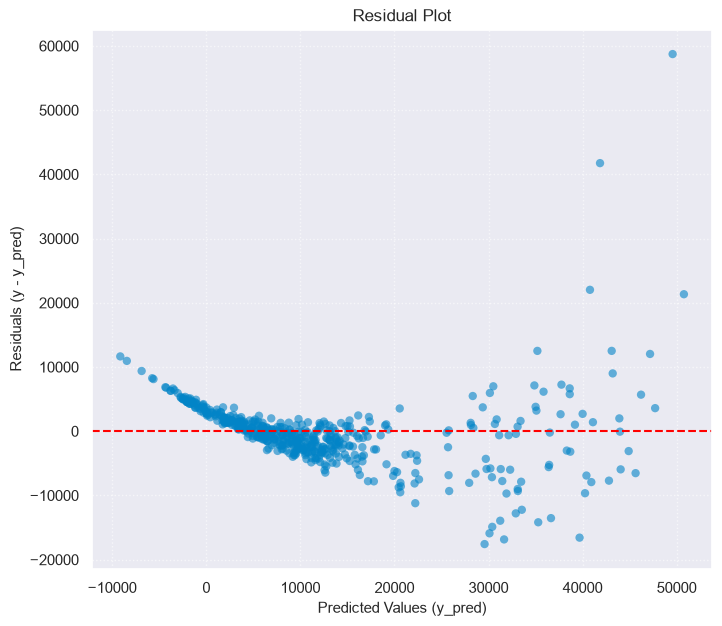

In [ ]:
predictions = model.predict(X_test)
residuals = y_test - predictions

plt.figure(figsize=(8, 7))
plt.scatter(predictions, residuals, alpha=0.6, color='#0284c7', edgecolors='none')
plt.axhline(0, color='red', linestyle='--', linewidth=1.5)

plt.title("Residual Plot", fontsize=12)
plt.xlabel("Predicted Values (y_pred)", fontsize=11)
plt.ylabel("Residuals (y - y_pred)", fontsize=11)

plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

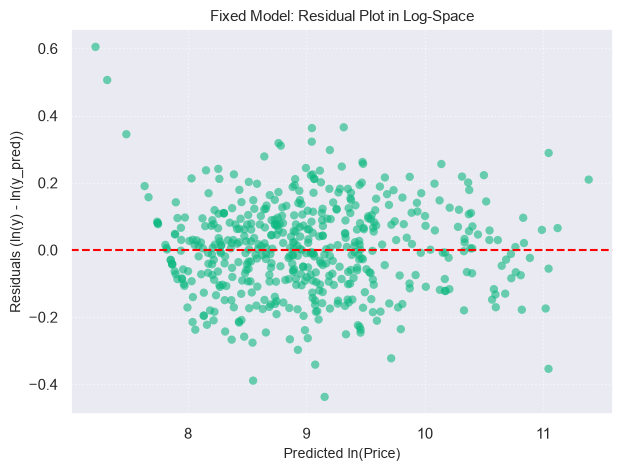

In [ ]:
y_train_log = np.log(y_train)
model_log = LinearRegression().fit(X_train, y_train_log)

pred_log = model_log.predict(X_test)
final_preds = np.exp(pred_log)

residuals_dollar = y_test - pred_log
residuals_log = np.log(y_test) - pred_log

plt.figure(figsize=(7, 5))
plt.scatter(
    pred_log, residuals_log, alpha=0.6, color="#10b981", edgecolors="none"
)
plt.axhline(0, color="red", linestyle="--", linewidth=1.5)

plt.title("Fixed Model: Residual Plot in Log-Space", fontsize=11)
plt.xlabel("Predicted ln(Price)", fontsize=10)
plt.ylabel("Residuals (ln(y) - ln(y_pred))", fontsize=10)
plt.grid(True, linestyle=":", alpha=0.6)
plt.show()

In [163]:
pred_train = np.exp(model_log.predict(X_train))
pred_test = np.exp(model_log.predict(X_test))

n = len(X_test)
k = X_test.shape[1]
r2_te = r2_score(y_test, pred_test)
adj_r2 = 1 - (1 - r2_te) * (n - 1) / (n - k - 1)

report_log = pd.Series(
    {
        "MAE ($)": mean_absolute_error(y_test, pred_test),
        "MedAE ($)": median_absolute_error(y_test, pred_test),
        "RMSE ($)": np.sqrt(mean_squared_error(y_test, pred_test)),
        "MAPE (%)": mean_absolute_percentage_error(y_test, pred_test) * 100,
        "R² (Test)": r2_te,
        "Adjusted R²": adj_r2,
        "R² (Train)": r2_score(y_train, pred_train),
    }
).round(2)

print("RESULT AFTER LOG-TRANSFORMATION")
print(report_log)

RESULT AFTER LOG-TRANSFORMATION
MAE ($)        1256.88
MedAE ($)       675.61
RMSE ($)       2374.66
MAPE (%)         10.53
R² (Test)         0.96
Adjusted R²       0.96
R² (Train)        0.96
dtype: float64
